# CBIM Problem Canvas


## Situation (S)
**What is the current state? What exists today in terms of data and process?**

The company currently operates 12 retail stores across Andhra Pradesh, covering cities such as Vijayawada, Guntur, Rajahmundry, Tirupati, Nellore, and Kakinada. It has six months of historical sales data from January to June 2026, covering five major product categories.

At present, the historical data is available for analysis, so the business can understand past sales performance across stores and categories. However, the weekly sales reporting process is not yet automated. This means management does not have a simple, repeatable weekly process to quickly compare current sales with historical performance and identify areas that need attention.

## Complication (C)

**What problem or gap exists? What is the operations head unable to do right now?**

The Head of Retail Operations needs to decide where to focus the Q3 promotional budget, but the current process mainly depends on manually analysing sales data. This makes it difficult to get a consistent weekly view of which stores and categories are performing well or falling behind.

There is also no automated process to check the quality of new weekly sales data before using it for business decisions. As a result, the Operations Head cannot quickly and confidently identify current performance issues and take timely action.

## Question (Q)

**What is the specific business question this use case must answer — for both the analysis and the automation?**

The main question is: Which stores and product categories need the most attention when planning Q3 promotional spending, based on their historical sales performance?

At the same time, we want to know whether the latest week's sales are following the normal six-month trend or showing any significant changes that need immediate attention.

## SSOT

**What is the single source of truth? For Part 1 — the historical CSV. For Part 2 — the weekly API response. How do they relate?**

For Part 1, the historical CSV dataset is our source of truth. It contains six months of sales data and helps us understand the normal sales pattern across stores and product categories.

For Part 2, the weekly API JSON response is our source of truth for the latest week's sales. It tells us what is happening right now.

The two sources work together: the CSV gives us the historical baseline, while the weekly JSON gives us the current performance signal. By comparing the latest week's results with the historical baseline, we can identify meaningful changes or alerts.

## Success definition

**How will you know this use case was successful? One metric for Part 1, one for Part 2.**

**Part 1** — Historical Analysis:
Success means using the six-month sales data to identify clear and data-backed business insights — such as which stores are performing strongly or weakly, which categories are improving or declining, when sales are strongest, and where unusual drops occurred. These findings should help the business make a more informed Q3 promotional decision.

**Part 2** — Weekly Pipeline:
Success means creating a repeatable weekly process that can take the latest JSON data, check whether the data is valid, calculate store and category performance, compare the current week with the historical baseline, and highlight important category alerts. The process should then produce a clear weekly summary without errors.

## Primary stakeholder

**Who is this for? What decisions do they need to make, and when?**

Our primary stakeholder is the Head of Retail Operations. She is responsible for deciding where the Q3 promotional budget should be spent, based on store and category performance.

She needs a reliable weekly sales update, preferably refreshed every Monday morning, so that she can quickly see which stores or categories are performing well, which ones need attention, and whether any unusual changes have occurred.



##**PART 1 — Retail Sales Pulse: Exploratory Data Analysis**

## 5.1 Load and inspect the data


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the historical retail sales dataset
df = pd.read_csv("MUC01_Retail_Sales_Dataset.csv")

# Display the first 5 rows
df.head()

,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN000001,2026-01-01,S01,Vijayawada,Electronics,Smart TV,2,3075.46,5843.37,5
1,TXN000002,2026-01-01,S01,Vijayawada,Electronics,Laptop,1,11598.06,11598.06,0
2,TXN000003,2026-01-01,S01,Vijayawada,Electronics,Tablet,3,5738.37,15493.60,10
3,TXN000004,2026-01-01,S01,Vijayawada,Electronics,Smart TV,3,3281.28,9351.65,5
4,TXN000005,2026-01-01,S01,Vijayawada,Apparel,Jeans,1,1917.14,1917.14,0


In [43]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (107836, 10)


In [44]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107836 entries, 0 to 107835
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   transaction_id  107836 non-null  object 
 1   date            107836 non-null  object 
 2   store_id        107836 non-null  object 
 3   store_city      107836 non-null  object 
 4   category        107836 non-null  object 
 5   product_name    107836 non-null  object 
 6   units_sold      107836 non-null  int64  
 7   unit_price      107836 non-null  float64
 8   revenue         107836 non-null  float64
 9   discount_pct    107836 non-null  int64  
dtypes: float64(2), int64(2), object(6)
memory usage: 8.2+ MB


In [45]:
# Check for missing/null values in each column
df.isnull().sum()

,0
transaction_id,0
date,0
store_id,0
store_city,0
category,0
product_name,0
units_sold,0
unit_price,0
revenue,0
discount_pct,0


In [46]:
# Generate descriptive statistics for numerical columns
df.describe()

,units_sold,unit_price,revenue,discount_pct
count,107836.000000,107836.000000,107836.000000,107836.000000
mean,2.583488,1778.097787,4263.920924,7.228152
std,1.471616,5053.631792,14243.244169,6.730445
min,1.000000,50.020000,40.040000,0.000000
25%,1.000000,274.827500,467.772500,0.000000
50%,2.000000,488.450000,1034.615000,5.000000
75%,3.000000,1039.522500,2473.335000,10.000000
max,13.000000,44990.140000,355090.880000,20.000000


In [47]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Check the date data type
print("Date data type:", df["date"].dtype)

# Check the date range
print("Date range:", df["date"].min(), "to", df["date"].max())

Date data type: datetime64[ns]
Date range: 2026-01-01 00:00:00 to 2026-06-30 00:00:00


### Business observations from descriptive statistics

The dataset has 107,836 sales transactions from 12 stores and 5 product categories covering January to June 2026. There are no missing values, so the data is ready for analysis.

The six months of historical sales data can help us understand which stores and categories are performing well or poorly. This data will also be used later as a baseline to compare the latest weekly sales.


## 5.2 Revenue by Store

I calculated the total six-month revenue for each store and ranked the stores from highest to lowest. I then created a horizontal bar chart to compare store performance and highlighted the top three and bottom three stores separately.


In [9]:
# Calculate total revenue by store
store_revenue = (
    df.groupby(["store_id", "store_city"])["revenue"]
      .sum()
      .reset_index()
      .sort_values("revenue", ascending=False)
)

# Display the store revenue ranking
store_revenue

,store_id,store_city,revenue
0,S01,Vijayawada,16391783.07
2,S03,Guntur,15414303.22
6,S07,Tirupati,14631409.18
5,S06,Rajahmundry,13410673.04
3,S04,Guntur,12679833.84
1,S02,Vijayawada,12053645.76
7,S08,Tirupati,10109035.33
10,S11,Kakinada,9552356.49
8,S09,Nellore,8651987.76
4,S05,Rajahmundry,6719567.13


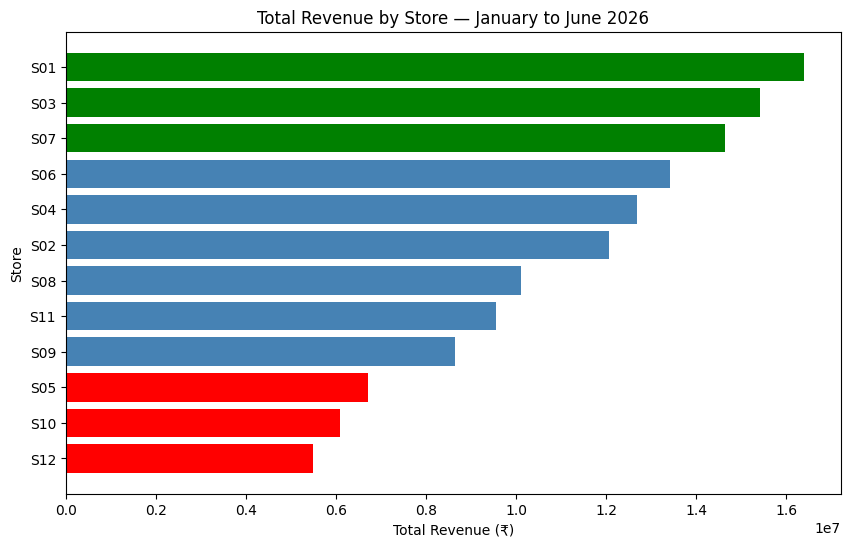

In [12]:
# Sort stores from lowest to highest revenue
plot_data = store_revenue.sort_values("revenue")

# Create colors for the bars
colors = ["red" if i < 3 else "green" if i >= 9 else "steelblue"
          for i in range(len(plot_data))]

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["store_id"],
    plot_data["revenue"],
    color=colors
)

plt.title("Total Revenue by Store — January to June 2026")
plt.xlabel("Total Revenue (₹)")
plt.ylabel("Store")

plt.show()

### Business interpretation

S01 Vijayawada is the strongest-performing store, generating approximately ₹5.91 crore in six-month revenue, followed by S03 Guntur at ₹5.32 crore and S07 Tirupati at ₹4.85 crore. In contrast, S12 Kakinada, S10 Nellore, and S05 Rajahmundry are the bottom three stores, each generating less than ₹2.6 crore. This performance gap suggests that promotional investment and operational attention should be differentiated across stores rather than applying the same approach everywhere.


## 5.3 Category Performance Over Time

I analyzed monthly revenue for each product category from January to June 2026 and plotted the trends over time. The chart helps identify which categories are declining most sharply and which categories are relatively stable.


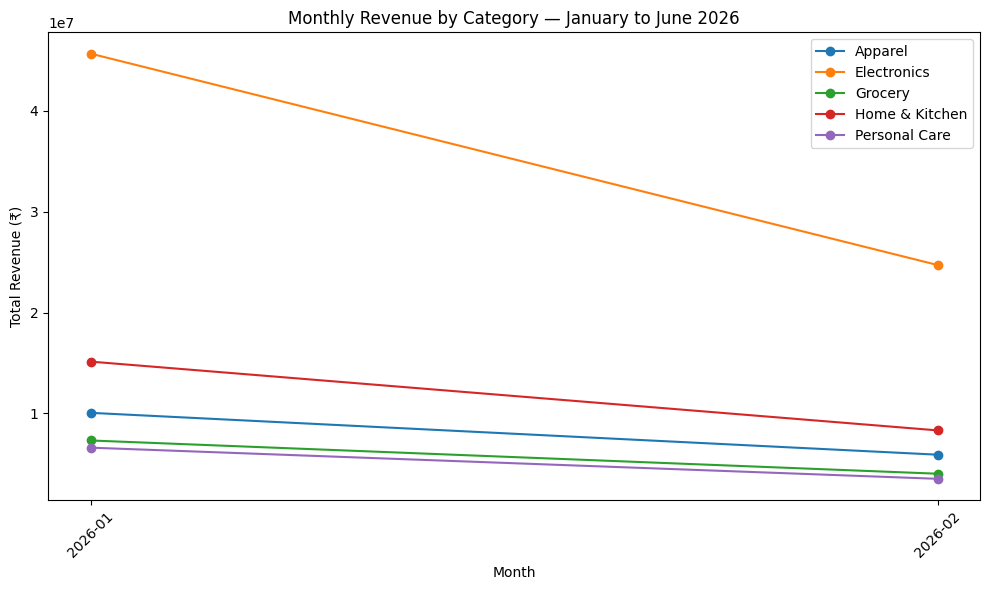

In [16]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Create month column
df["month"] = df["date"].dt.to_period("M").astype(str)

# Calculate monthly revenue by category
category_monthly = (
    df.groupby(["month", "category"])["revenue"]
      .sum()
      .reset_index()
)

# Create line chart
plt.figure(figsize=(10, 6))

for category in category_monthly["category"].unique():
    data = category_monthly[category_monthly["category"] == category]
    plt.plot(data["month"], data["revenue"], marker="o", label=category)

plt.title("Monthly Revenue by Category — January to June 2026")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Business interpretation

Electronics shows the steepest decline in revenue, falling by approximately 35% from January to June, which signals a need to investigate the reasons for weakening demand. Personal Care is the most stable category, with revenue remaining relatively consistent over the six-month period, while Apparel shows a strong upward trend.


## 5.4 Day-of-Week and Monthly Patterns

I analyzed average daily revenue by day of the week and total revenue by month. This helps identify the strongest and weakest sales periods and determine when a flash promotion could have the greatest business impact.


Average Daily Revenue by Day of Week:


,revenue
day_of_week,
Monday,2.053280e+06
Tuesday,2.311233e+06
Wednesday,2.190046e+06
Thursday,2.338674e+06
Friday,2.703238e+06
Saturday,3.937183e+06
Sunday,3.208861e+06



Total Revenue by Month:


,revenue
month,
2026-01,84768131.10
2026-02,46429482.67
NaT,0.00


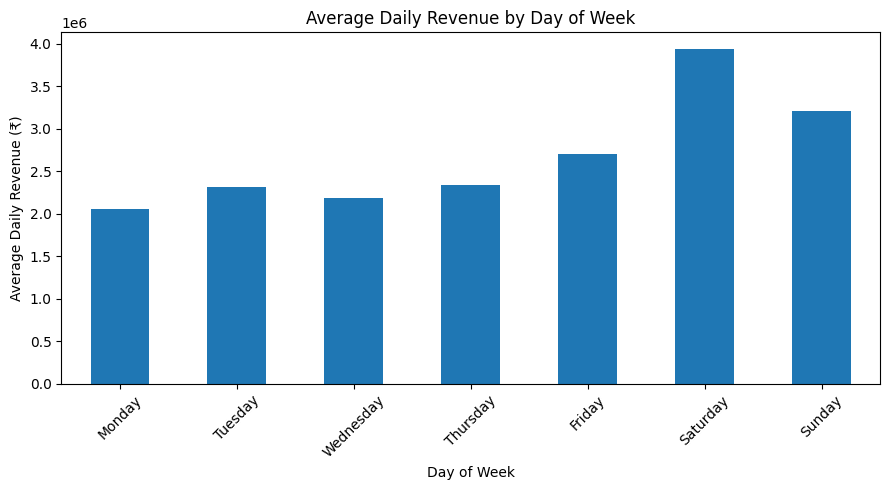

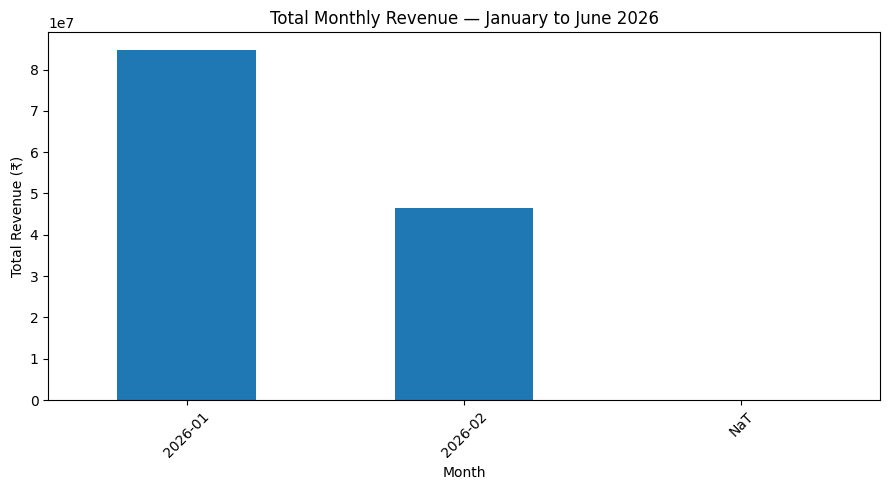

In [22]:
# ==========================================
# 5.4 Day-of-Week and Monthly Revenue Patterns
# ==========================================

# Create day-of-week column
df["day_of_week"] = df["date"].dt.day_name()

# First calculate total revenue for each date
daily_revenue = (
    df.groupby(["date", "day_of_week"])["revenue"]
      .sum()
      .reset_index()
)

# Calculate average daily revenue by day of week
weekday_revenue = (
    daily_revenue.groupby("day_of_week")["revenue"]
    .mean()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

# Calculate total revenue by month
monthly_revenue = (
    df.groupby("month")["revenue"]
      .sum()
)

# Display the results
print("Average Daily Revenue by Day of Week:")
display(weekday_revenue)

print("\nTotal Revenue by Month:")
display(monthly_revenue)

# ------------------------------------------
# Weekday Revenue Chart
# ------------------------------------------

plt.figure(figsize=(9, 5))

weekday_revenue.plot(kind="bar")

plt.title("Average Daily Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Revenue (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# ------------------------------------------
# Monthly Revenue Chart
# ------------------------------------------

plt.figure(figsize=(9, 5))

monthly_revenue.plot(kind="bar")

plt.title("Total Monthly Revenue — January to June 2026")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
# Calculate total revenue by month
monthly_revenue = (
    df.groupby("month")["revenue"]
      .sum()
)

print(monthly_revenue)

month
2026-01    84768131.10
2026-02    73833666.23
2026-03    80689884.84
2026-04    75670487.12
2026-05    75559873.38
2026-06    69282134.11
Name: revenue, dtype: float64


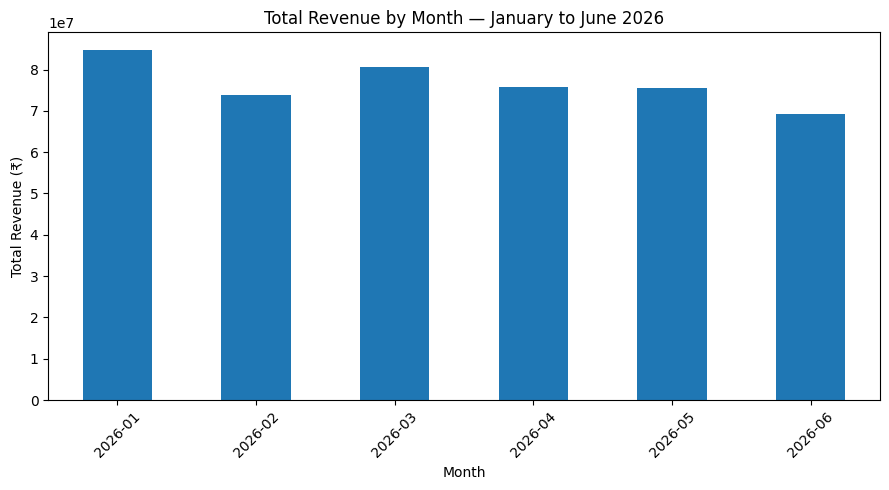

In [31]:
plt.figure(figsize=(9, 5))
monthly_revenue.plot(kind="bar")
plt.title("Total Revenue by Month — January to June 2026")
plt.xlabel("Month")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Saturday recorded the highest average daily revenue, while Monday recorded the lowest, showing that customer demand is stronger toward the weekend. This suggests that a flash promotion on Monday could help stimulate demand during the weaker weekday. January had the highest monthly revenue at approximately ₹8.48 crore, while June had the lowest at approximately ₹6.93 crore, showing a decline in overall monthly sales toward the end of the six-month period. These patterns can help the business plan promotions around weaker days and investigate the reasons for the recent decline in sales.

## 5.5 Anomaly Identification

I calculated weekly revenue for each store and compared each store-week against that store's own average weekly revenue. I flagged store-weeks where revenue was more than two standard deviations below the store's average, then considered plausible business reasons for the unusual decline.


In [32]:
# Create week column (Monday to Sunday)
df["week"] = df["date"].dt.to_period("W-SUN")

# Calculate weekly revenue by store
weekly_store_revenue = (
    df.groupby(["store_id", "store_city", "week"])["revenue"]
      .sum()
      .reset_index()
)

# Keep only complete weeks inside the six-month period
weekly_store_revenue = weekly_store_revenue[
    (weekly_store_revenue["week"].apply(lambda x: x.start_time) >= pd.Timestamp("2026-01-01")) &
    (weekly_store_revenue["week"].apply(lambda x: x.end_time) <= pd.Timestamp("2026-06-30"))
]

# Calculate average and standard deviation for each store
store_stats = (
    weekly_store_revenue.groupby("store_id")["revenue"]
    .agg(["mean", "std"])
    .reset_index()
)

# Add store statistics
weekly_store_revenue = weekly_store_revenue.merge(
    store_stats,
    on="store_id"
)

# Find anomalies: more than 2 standard deviations below the store average
anomalies = weekly_store_revenue[
    weekly_store_revenue["revenue"] <
    weekly_store_revenue["mean"] - 2 * weekly_store_revenue["std"]
]

# Display anomalies
anomalies

,store_id,store_city,week,revenue,mean,std
44,S02,Vijayawada,2026-05-18/2026-05-24,1173289.36,1.627619e+06,226809.226710
97,S04,Guntur,2026-06-08/2026-06-14,1137480.32,1.598816e+06,228635.581011
105,S05,Rajahmundry,2026-02-09/2026-02-15,655732.19,9.774069e+05,127113.547805
238,S10,Nellore,2026-04-06/2026-04-12,505536.54,8.671293e+05,163809.391223


### Business interpretation

Four store-weeks were flagged as unusually low compared with their respective store averages: S02 Vijayawada (May 18–24), S04 Guntur (June 8–14), S05 Rajahmundry (February 9–15), and S10 Nellore (April 6–12). These anomalies could indicate issues such as a local event, supply disruption, pricing problem, or competitor activity; for example, the sharp decline at S05 Rajahmundry could warrant checking pricing and competitor activity during February 9–15.


## Business Recommendation

The most important finding is that store performance varies significantly. **S01 Vijayawada generated the highest six-month revenue of approximately ₹5.91 crore, while S12 Kakinada generated the lowest at approximately ₹2.20 crore.** The business should give more attention to S12 Kakinada by checking its promotions, stock availability, and local competition. Additional store-level data on inventory, promotions, local events, and competitor activity would help explain the difference in performance.


## 5.7 Understand JSON Structure

I inspected the weekly sales JSON response to understand its structure before building the data pipeline. I identified the top-level keys, located the transaction records, and reviewed the metadata provided with the sales data.


In [34]:
import json

# Load the clean weekly sales JSON
with open("MUC01_Weekly_Sales_API_Response.json", "r") as file:
    weekly_data = json.load(file)

# Display the top-level keys
print("Top-level keys:")
print(weekly_data.keys())

# Display the JSON structure
print("\nJSON structure:")
print(weekly_data)

Top-level keys:
dict_keys(['status', 'request_id', 'generated_at', 'period', 'record_count', 'data'])

JSON structure:
{'status': 'success', 'request_id': 'RTL-20260630-001', 'generated_at': '2026-06-30T08:00:00Z', 'period': {'from': '2026-06-24', 'to': '2026-06-30'}, 'record_count': 4291, 'data': [{'transaction_id': 'TXN103546', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Electronics', 'product_name': 'Headphones', 'units_sold': 3, 'unit_price': 13899.23, 'revenue': 41697.69, 'discount_pct': 0}, {'transaction_id': 'TXN103547', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Apparel', 'product_name': 'Formal Shirt', 'units_sold': 2, 'unit_price': 1470.83, 'revenue': 2941.66, 'discount_pct': 0}, {'transaction_id': 'TXN103548', 'date': '2026-06-24', 'store_id': 'S01', 'store_city': 'Vijayawada', 'category': 'Apparel', 'product_name': 'Saree', 'units_sold': 4, 'unit_price': 2706.78, 'revenue': 10827.12, 'discount_pct'

### Business Interpretation

The JSON response contains both weekly sales data and metadata about the API request. The `data` key contains the individual transaction records, while `period` shows the reporting week and `record_count` shows how many transactions were returned. In a real production API, this structure helps the pipeline identify the correct sales records and check whether the expected amount of data was received before processing it.


## 5.8 Ingest and Parse Clean JSON

I loaded the clean weekly sales JSON and converted the transaction data into a pandas DataFrame. I also converted the transaction date to datetime format and compared the API metadata record count with the actual number of records loaded. Finally, I checked the reporting period from the metadata and displayed the first five transactions.


In [35]:
# Convert transaction data into a DataFrame
weekly_df = pd.DataFrame(weekly_data["data"])

# Convert date column to datetime
weekly_df["date"] = pd.to_datetime(weekly_df["date"])

# Check record count
actual_record_count = len(weekly_df)
expected_record_count = weekly_data["record_count"]

print("Expected record count:", expected_record_count)
print("Actual record count:", actual_record_count)

# Print reporting period
print("\nReporting period:")
print("From:", weekly_data["period"]["from"])
print("To:", weekly_data["period"]["to"])

# Display first 5 rows
print("\nFirst 5 rows:")
weekly_df.head()

Expected record count: 4291
Actual record count: 4291

Reporting period:
From: 2026-06-24
To: 2026-06-30

First 5 rows:


,transaction_id,date,store_id,store_city,category,product_name,units_sold,unit_price,revenue,discount_pct
0,TXN103546,2026-06-24,S01,Vijayawada,Electronics,Headphones,3,13899.23,41697.69,0
1,TXN103547,2026-06-24,S01,Vijayawada,Apparel,Formal Shirt,2,1470.83,2941.66,0
2,TXN103548,2026-06-24,S01,Vijayawada,Apparel,Saree,4,2706.78,10827.12,0
3,TXN103549,2026-06-24,S01,Vijayawada,Apparel,Saree,3,3257.93,9773.79,0
4,TXN103550,2026-06-24,S01,Vijayawada,Apparel,Jeans,1,2118.31,2118.31,0


### Business Interpretation

The expected record count and actual record count are both 4,291, so the weekly data appears to have been received completely. Production pipelines check the record count because missing or extra records could indicate an incomplete or incorrect API response and could affect the accuracy of the weekly sales report.


## 5.9 Validate Corrupt JSON

I loaded the corrupt weekly sales JSON and validated the transaction records for three key data-quality issues: missing values, non-positive revenue, and invalid store IDs. The validation results will show whether the pipeline should continue processing or stop because the input data contains errors.


In [48]:
def validate_weekly_sales(dataframe):
    """
    Validate the weekly sales data before it enters the pipeline.
    """

    # Check for null values
    null_values = dataframe.isnull().sum()
    null_issues = null_values[null_values > 0]

    # Check for revenue <= 0
    invalid_revenue = dataframe[dataframe["revenue"] <= 0]

    # Check for invalid store IDs
    valid_store_ids = [f"S{i:02d}" for i in range(1, 13)]

    invalid_store_ids = dataframe[
        ~dataframe["store_id"].isin(valid_store_ids)
    ]

    # Count total issues
    total_issues = (
        null_values.sum()
        + len(invalid_revenue)
        + len(invalid_store_ids)
    )

    # Print validation summary
    print("VALIDATION SUMMARY")
    print("------------------")
    print("Total records:", len(dataframe))

    print("\nNull values:")
    null_rows = dataframe[dataframe.isnull().any(axis=1)]

    if len(null_rows) > 0:
        display(
            null_rows[
                ["transaction_id", "units_sold"]
            ]
        )
    else:
        print("No null values found.")

    print("\nRevenue <= 0:")
    display(
        invalid_revenue[
            ["transaction_id", "revenue"]
        ]
    )

    print("\nInvalid store IDs:")
    display(
        invalid_store_ids[
            ["transaction_id", "store_id"]
        ]
    )

    print("\nTotal issues found:", total_issues)

    if total_issues == 0:
        print("Pipeline status: PASSED")
        return True
    else:
        print("Pipeline status: FAILED")
        print("Pipeline should be halted for data-quality review.")
        return False


# Load the corrupt weekly sales JSON
with open("MUC01_Weekly_Sales_API_Corrupt.json", "r") as file:
    corrupt_data = json.load(file)

# Convert transaction data into a DataFrame
corrupt_df = pd.DataFrame(corrupt_data["data"])

# Run validation
validation_passed = validate_weekly_sales(corrupt_df)

VALIDATION SUMMARY
------------------
Total records: 4291

Null values:


,transaction_id,units_sold
12,TXN103558,NaN



Revenue <= 0:


,transaction_id,revenue
5,TXN103551,-150.0



Invalid store IDs:


,transaction_id,store_id
20,TXN103566,S99



Total issues found: 3
Pipeline status: FAILED
Pipeline should be halted for data-quality review.


### Validation Summary

The corrupt weekly sales file contains three data-quality issues: one null `units_sold` value, one non-positive revenue value, and one invalid store ID. The validation function checks these conditions before the data is allowed into the processing pipeline. Because the data contains quality issues, the pipeline should be halted for data-quality review rather than silently skipping or changing the affected records. This protects the reliability of the weekly sales summary.

## 5.10 Transform and Aggregate Clean JSON

I transformed the clean weekly API data into store-level and category-level revenue summaries. I also compared each category's weekly revenue with its six-month historical daily average from the CSV dataset. A category alert is raised when weekly revenue is more than 20% below its expected weekly baseline.


In [39]:
# Weekly revenue by store
weekly_revenue_by_store = (
    weekly_df.groupby(["store_id", "store_city"])["revenue"]
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
)

# Weekly revenue by category
weekly_revenue_by_category = (
    weekly_df.groupby("category")["revenue"]
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
)

# Top store this week
top_store_this_week = weekly_revenue_by_store.iloc[0]

# Six-month average daily revenue by category
category_daily_average = (
    df.groupby("category")["revenue"].sum() / df["date"].nunique()
)

# Expected revenue for one week
category_weekly_expected = category_daily_average * 7

# Compare weekly revenue with historical baseline
category_alert = weekly_revenue_by_category.copy()

category_alert["expected_weekly_revenue"] = (
    category_alert["category"].map(category_weekly_expected)
)

category_alert["change_pct"] = (
    (category_alert["revenue"] - category_alert["expected_weekly_revenue"])
    / category_alert["expected_weekly_revenue"]
    * 100
)

# Alert when revenue is more than 20% below baseline
category_alert["alert"] = category_alert["change_pct"] < -20

# Show results
print("Weekly Revenue by Store:")
display(weekly_revenue_by_store)

print("Weekly Revenue by Category:")
display(weekly_revenue_by_category)

print("Top Store This Week:")
print(top_store_this_week)

print("Category Alert:")
display(category_alert)

Weekly Revenue by Store:


,store_id,store_city,revenue
2,S03,Guntur,2037560.19
0,S01,Vijayawada,1608043.08
5,S06,Rajahmundry,1565006.35
6,S07,Tirupati,1349795.33
3,S04,Guntur,1285265.18
7,S08,Tirupati,1269260.54
10,S11,Kakinada,1249928.27
1,S02,Vijayawada,1218330.60
8,S09,Nellore,976322.30
4,S05,Rajahmundry,941961.76


Weekly Revenue by Category:


,category,revenue
1,Electronics,5764693.85
0,Apparel,3228573.10
3,Home & Kitchen,2847057.00
2,Grocery,1617278.70
4,Personal Care,1557807.63


Top Store This Week:
store_id             S03
store_city        Guntur
revenue       2037560.19
Name: 2, dtype: object
Category Alert:


,category,revenue,expected_weekly_revenue,change_pct,alert
1,Electronics,5764693.85,8.760741e+06,-34.198557,True
0,Apparel,3228573.10,2.687056e+06,20.152805,False
3,Home & Kitchen,2847057.00,3.165304e+06,-10.054236,False
2,Grocery,1617278.70,1.636011e+06,-1.145023,False
4,Personal Care,1557807.63,1.533370e+06,1.593738,False


### Business Interpretation

S03 Guntur was the top-performing store this week, generating approximately ₹20.38 lakh, while S10 Nellore generated the lowest revenue at approximately ₹6.27 lakh. Electronics generated the highest weekly category revenue at approximately ₹57.65 lakh, but it was 34.20% below its six-month expected weekly level, triggering an alert. This suggests that the business should investigate the reason for the decline in Electronics sales this week.


## 5.11 Generate Weekly Summary

I created a function to generate a structured weekly sales summary using the clean API data and the calculated store and category results. The summary includes the reporting period, number of records, top and bottom stores, category alerts, categories with no alerts, and the overall pipeline status.


In [49]:
def generate_weekly_summary(json_file):
    """
    Generate the weekly retail sales summary from the clean JSON file.
    """

    # Load clean weekly JSON
    with open(json_file, "r") as file:
        weekly_data = json.load(file)

    # Convert transaction data into a DataFrame
    weekly_df_summary = pd.DataFrame(weekly_data["data"])

    # Calculate weekly revenue by store
    weekly_store_summary = (
        weekly_df_summary
        .groupby(["store_id", "store_city"])["revenue"]
        .sum()
        .reset_index()
        .sort_values("revenue", ascending=False)
    )

    # Calculate weekly revenue by category
    weekly_category_summary = (
        weekly_df_summary
        .groupby("category")["revenue"]
        .sum()
        .reset_index()
    )

    # Calculate historical weekly baseline from CSV
    category_daily_average = (
        df.groupby("category")["revenue"].sum()
        / df["date"].nunique()
    )

    category_weekly_expected = category_daily_average * 7

    # Compare current week with historical baseline
    weekly_category_summary["expected_weekly_revenue"] = (
        weekly_category_summary["category"]
        .map(category_weekly_expected)
    )

    weekly_category_summary["change_pct"] = (
        (weekly_category_summary["revenue"]
         - weekly_category_summary["expected_weekly_revenue"])
        / weekly_category_summary["expected_weekly_revenue"]
    ) * 100

    weekly_category_summary["alert"] = (
        weekly_category_summary["change_pct"] < -20
    )

    # Identify top and bottom stores
    top_store = weekly_store_summary.iloc[0]
    bottom_store = weekly_store_summary.iloc[-1]

    # Display summary
    print("=== RETAIL SALES PULSE — WEEKLY SUMMARY ===")
    print("--------------------------------------------")
    print(
        "Period:",
        weekly_data["period"]["from"],
        "to",
        weekly_data["period"]["to"]
    )
    print("Records processed:", weekly_data["record_count"])

    print(
        "\nTop store:",
        top_store["store_id"],
        top_store["store_city"],
        "₹",
        round(top_store["revenue"], 2)
    )

    print(
        "Bottom store:",
        bottom_store["store_id"],
        bottom_store["store_city"],
        "₹",
        round(bottom_store["revenue"], 2)
    )

    # Category alerts
    alerts = weekly_category_summary[
        weekly_category_summary["alert"] == True
    ]

    print("\nCategory Alerts:")

    if len(alerts) > 0:
        for _, row in alerts.iterrows():
            print(
                row["category"],
                ":",
                round(row["change_pct"], 2),
                "% below historical baseline"
            )
    else:
        print("No category alerts.")

    # Categories without alerts
    no_alerts = weekly_category_summary[
        weekly_category_summary["alert"] == False
    ]

    print("\nCategories with No Alert:")
    print(", ".join(no_alerts["category"]))

    print("\nPipeline Status: COMPLETED SUCCESSFULLY")


# Generate the weekly summary from the clean JSON file
generate_weekly_summary("MUC01_Weekly_Sales_API_Response.json")

=== RETAIL SALES PULSE — WEEKLY SUMMARY ===
--------------------------------------------
Period: 2026-06-24 to 2026-06-30
Records processed: 4291

Top store: S03 Guntur ₹ 2037560.19
Bottom store: S10 Nellore ₹ 627119.87

Category Alerts:
Electronics : -34.2 % below historical baseline

Categories with No Alert:
Apparel, Grocery, Home & Kitchen, Personal Care

Pipeline Status: COMPLETED SUCCESSFULLY


### Business Interpretation

The weekly summary gives the Operations Head a quick view of the current sales position without requiring the full analysis to be repeated manually. It shows the reporting period, records processed, strongest and weakest stores, and categories that have fallen more than 20% below their historical baseline. In this week, Electronics is the only category with an alert, at approximately 34.2% below the historical baseline. If this summary were emailed every Monday morning, I would add a short recommended action for each alert, week-over-week revenue change, and relevant context such as inventory availability or active promotions. This would help the Operations Head move from seeing an alert to deciding what action should be taken.